In [1]:
import scanpy as sc
import numpy as np
import random
import sys
sys.path.append("../../../mapqc/")
import mapqc
import plotting

In [2]:
query_dataset = "Sheppard_2020"

In [3]:
adata = sc.read_h5ad(f"./scanvi_models/{query_dataset}/emb.h5ad")

calculate umap:

In [ ]:
sc.pp.neighbors(adata,n_neighbors=30)

In [ ]:
sc.tl.umap(adata)

In [ ]:
adata.write(f"./scanvi_models/{query_dataset}/emb.h5ad")

### Run MapQC on healthy

In [4]:
n_nhoods = 500
k=1000

In [5]:
ref_q_key = "core_or_extension"
ref_cat = "core"
query_cat = "extension"
condition_key = "lung_condition"
batch_key = "dataset"

In [12]:
adata

AnnData object with n_obs × n_vars = 664964 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'tissue_detailed_unharmonized', 'tissu

In [16]:
adata.obs.loc[adata.obs[ref_q_key] == query_cat, "lung_condition"].unique()

['Systemic sclerosis-associated ILD', 'IPF', 'Healthy']
Categories (4, object): ['Healthy', 'Healthy (tumor adjacent)', 'IPF', 'Systemic sclerosis-associated ILD']

In [17]:
condition_of_interest = "Healthy"
print(f"Subsetting query to condition {condition_of_interest}")
adata_healthy = adata[
    (adata.obs[ref_q_key] == ref_cat)
    | (adata.obs[condition_key] == condition_of_interest)
].copy()

Subsetting query to condition Healthy


In [18]:
query_cell_idc = np.where(adata_healthy.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc = random.sample(query_cell_idc, k=n_nhoods)
center_cells = np.array(adata_healthy.obs.iloc[center_cell_idc, :].index)

In [19]:
results = mapqc.mapQC_results(
    adata=adata_healthy,
    center_cells=center_cells,
    k=k,
    ref_q_key=ref_q_key,
    ref_cat=ref_cat,
    query_cat=query_cat,
    batch_key="dataset"
)

In [20]:
results.calculate_sample_dists_to_ref_samples()

../../../mapqc/mapqc.py:180: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
../../../mapqc/mapqc.py:184: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/numpy/lib/nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [21]:
results.calculate_nhood_statistics()

47% of neighborhoods passed filtering.
2% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.


../../../mapqc/mapqc.py:249: RuntimeWarning: Mean of empty slice
  mean_zscored_q_dist_to_ref = np.nanmean(


/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


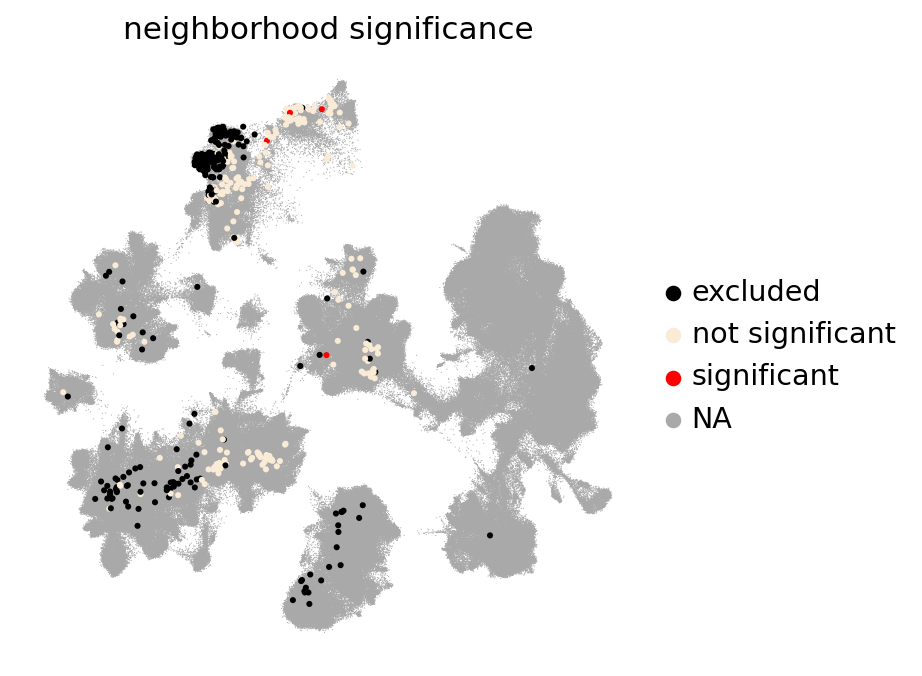

In [22]:
plotting.plot_umap_significance(results)

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


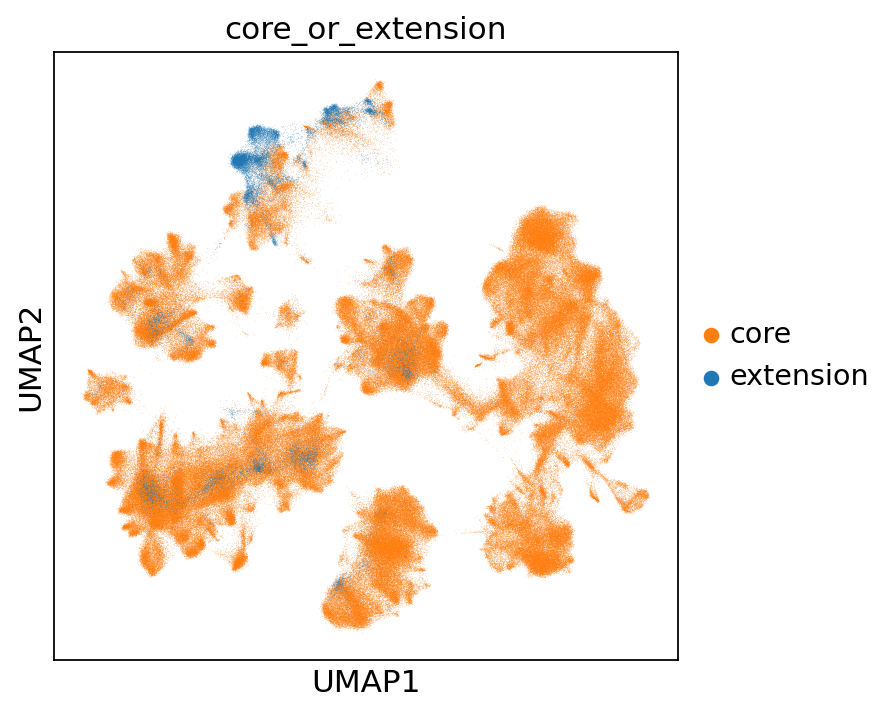

In [25]:
sc.pl.umap(results.adata,color="core_or_extension",palette={ref_cat:"tab:orange",query_cat:"tab:blue"})

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


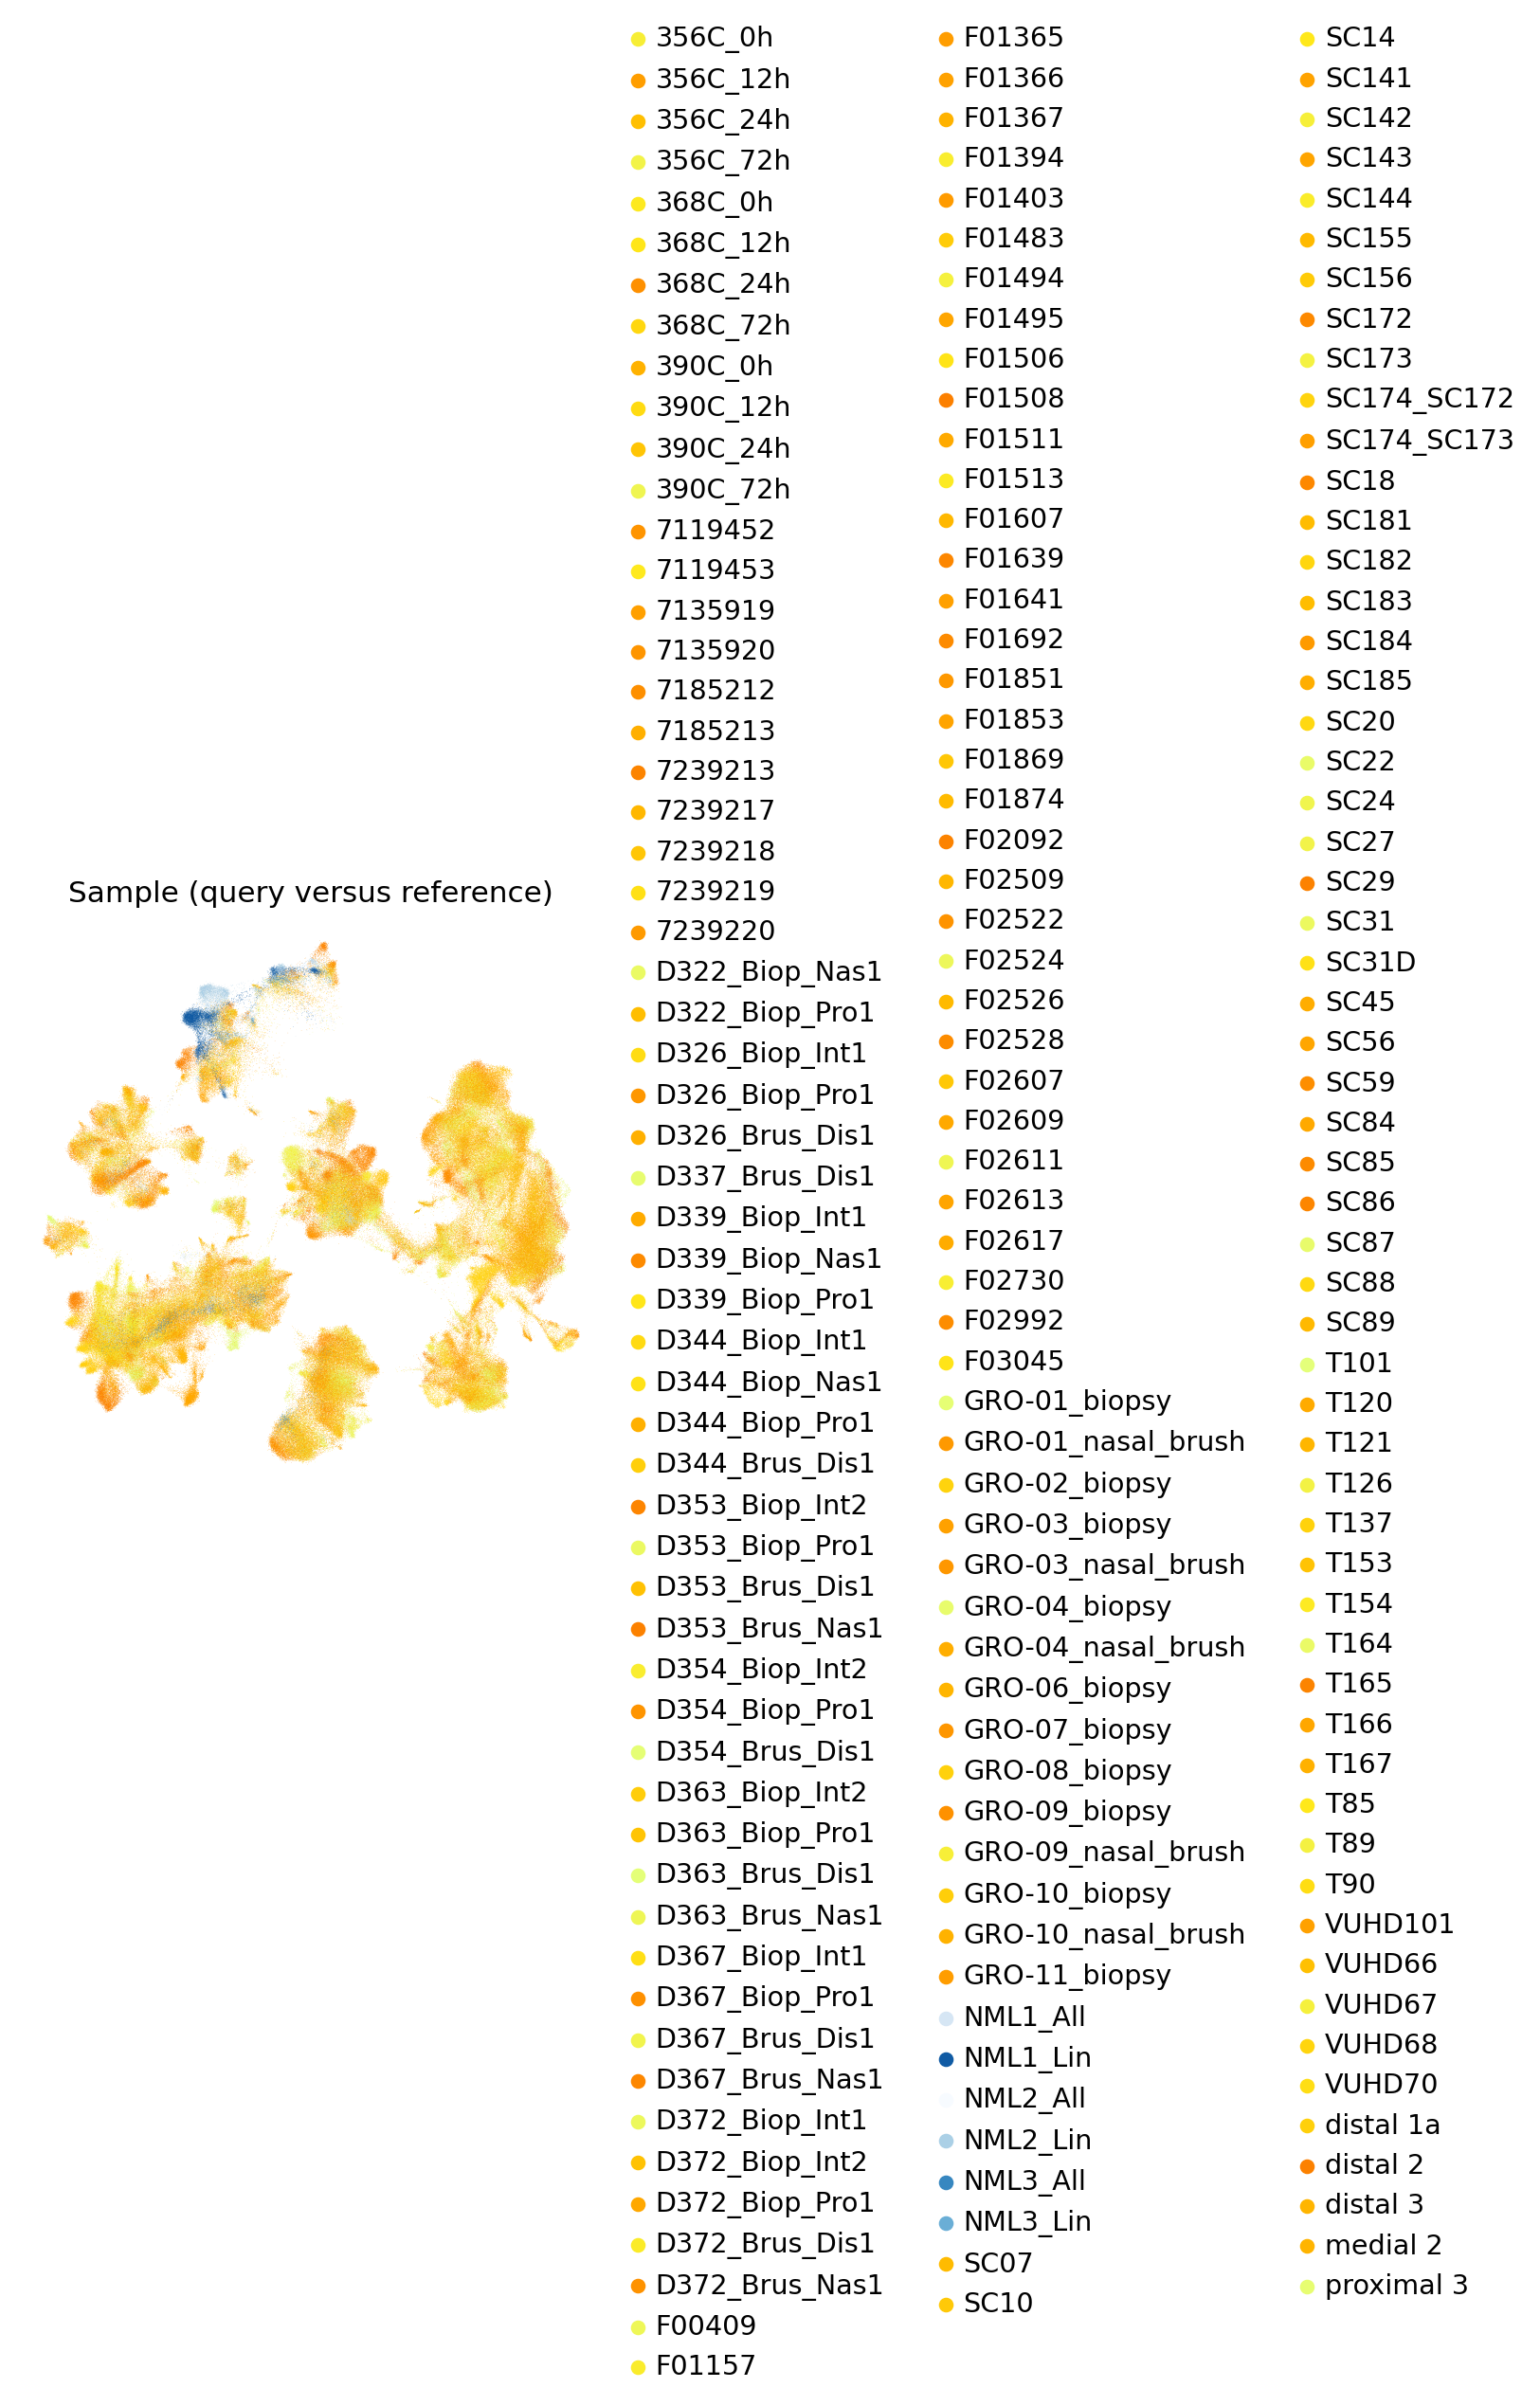

In [24]:
plotting.plot_umap_q_ref_sample_shaded(results,include_legend=True)

### Run mapQC on disease:

In [26]:
condition_of_interest_disease = "IPF"
print(f"Subsetting query to condition {condition_of_interest_disease}")
adata_disease = adata[
    (adata.obs[ref_q_key] == ref_cat)
    | (adata.obs[condition_key] == condition_of_interest_disease)
].copy()

Subsetting query to condition IPF


In [27]:
query_cell_idc_disease = np.where(adata_disease.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc_disease = random.sample(query_cell_idc_disease, k=n_nhoods)
center_cells_disease = np.array(adata_disease.obs.iloc[center_cell_idc_disease, :].index)

In [28]:
results_disease = mapqc.mapQC_results(
    adata=adata_disease,
    center_cells=center_cells_disease,
    k=k,
    ref_q_key=ref_q_key,
    ref_cat=ref_cat,
    query_cat=query_cat,
    batch_key="dataset"
)

In [29]:
results_disease.calculate_sample_dists_to_ref_samples()

../../../mapqc/mapqc.py:180: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
../../../mapqc/mapqc.py:184: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/numpy/lib/nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [30]:
results_disease.calculate_nhood_statistics()

22% of neighborhoods passed filtering.
54% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.


../../../mapqc/mapqc.py:249: RuntimeWarning: Mean of empty slice
  mean_zscored_q_dist_to_ref = np.nanmean(


/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


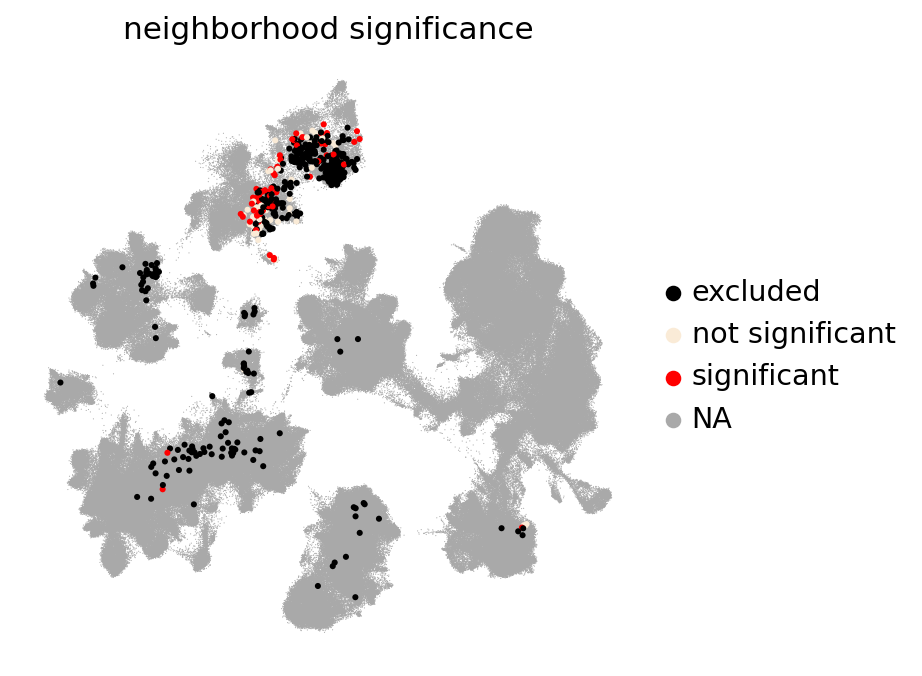

In [31]:
plotting.plot_umap_significance(results_disease)